### **Morphology: Erosion, Dilation, Opening, and Closing**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Computer_Vision_In_Python/blob/main/Algorithms/Erosion_and_Dilation.ipynb)

> Morphological operations process binary shapes with a small **structuring element**. **Erosion** shrinks white regions; **dilation** grows them. Combined, they form **opening** (erosion then dilation, removes small white specks) and **closing** (dilation then erosion, fills small black holes). This notebook extracts a boundary and cleans two noisy letters.

In [1]:
# Import libraries and helpers (images load from ../Images locally, or from GitHub in Colab)
import os
import urllib.request

import cv2
import numpy as np
from matplotlib import pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/jrafa1607/Computer_Vision_In_Python/main/Images/"

def load_image(name, flags=cv2.IMREAD_COLOR):
    """Returns the image in OpenCV format (BGR for color images)."""
    local = os.path.join("..", "Images", name)
    if os.path.exists(local):
        data = np.fromfile(local, np.uint8)
    else:
        with urllib.request.urlopen(BASE_URL + name) as response:
            data = np.frombuffer(response.read(), np.uint8)
    return cv2.imdecode(data, flags)

def show(images, titles, size=(14, 4)):
    """Shows images side by side; color images are converted from BGR to RGB for Matplotlib."""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

#### **01. Erosion and Boundary Extraction**

Erosion keeps a pixel white only if the whole structuring element fits inside the shape. Subtracting the eroded shape from the original leaves only the **boundary**.

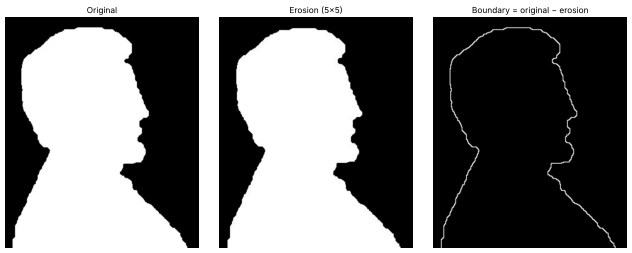

In [2]:
# Boundary extraction: original minus erosion
silhouette = load_image("ShadowMan.png", cv2.IMREAD_GRAYSCALE)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
eroded = cv2.erode(silhouette, kernel)
boundary = cv2.subtract(silhouette, eroded)
show([silhouette, eroded, boundary], ["Original", "Erosion (5x5)", "Boundary = original − erosion"], size=(13, 5))

#### **02. Closing: Filling Holes**

This letter has small **black holes** inside the stroke. Dilation fills them but makes the stroke thicker; the erosion that follows restores the original thickness. Together they are a **closing**.

Black regions (original): 35  (outer background + inside of the loop + holes)
Black regions (closing): 2  (outer background + inside of the loop + holes)


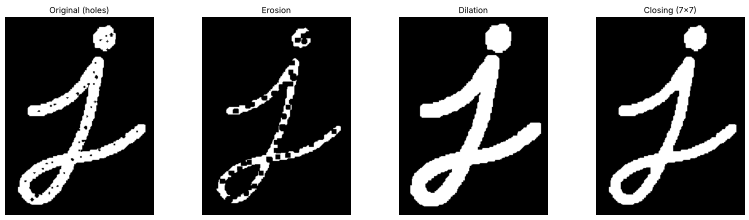

In [3]:
# Closing fills the holes inside the letter
def load_binary(name):
    _, binary = cv2.threshold(load_image(name, cv2.IMREAD_GRAYSCALE), 127, 255, cv2.THRESH_BINARY)
    return binary

def count_regions(binary):
    """Returns (white objects, black regions); black regions include the outer background."""
    white = cv2.connectedComponents((binary > 0).astype(np.uint8))[0] - 1
    black = cv2.connectedComponents((binary == 0).astype(np.uint8))[0] - 1
    return white, black

letter_holes = load_binary("letter_j.png")
kernel = np.ones((7, 7), np.uint8)
closed = cv2.morphologyEx(letter_holes, cv2.MORPH_CLOSE, kernel)
show([letter_holes, cv2.erode(letter_holes, kernel), cv2.dilate(letter_holes, kernel),
      closed],
     ["Original (holes)", "Erosion", "Dilation", "Closing (7x7)"], size=(16, 4.5))
for name, image in [("original", letter_holes), ("closing", closed)]:
    white, black = count_regions(image)
    print(f"Black regions ({name}): {black}  (outer background + inside of the loop + holes)")

#### **03. Opening: Removing Specks**

This letter has small **white specks** around it. Erosion removes them but thins the stroke; the dilation that follows restores it. Together they are an **opening**.

White objects (original): 29  (letter + dot + specks)
White objects (opening): 2  (letter + dot + specks)


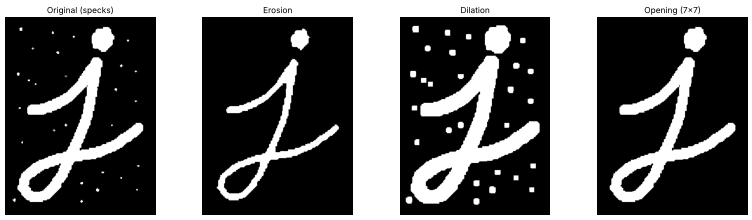

In [4]:
# Opening removes the specks around the letter
letter_specks = load_binary("letter_j2.png")
opened = cv2.morphologyEx(letter_specks, cv2.MORPH_OPEN, kernel)
show([letter_specks, cv2.erode(letter_specks, kernel), cv2.dilate(letter_specks, kernel), opened],
     ["Original (specks)", "Erosion", "Dilation", "Opening (7x7)"], size=(16, 4.5))
for name, image in [("original", letter_specks), ("opening", opened)]:
    print(f"White objects ({name}): {count_regions(image)[0]}  (letter + dot + specks)")

#### **Key Takeaways**

* Use **closing** for holes inside objects and **opening** for specks outside them.
* The structuring element must be larger than the noise and smaller than the details you want to keep.